# Decision Trees

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hamedheli/ml-from-scratch/blob/main/02-decision-trees/decision_trees.ipynb) [![View in nbviewer](https://img.shields.io/badge/view%20in-nbviewer-orange)](https://nbviewer.org/github/HamedHeli/ml-from-scratch/blob/main/02-decision-trees/decision_trees.ipynb)

Part of [Machine Learning From Scratch](../README.md). The code for this model is in this folder; shared helpers (data loading, plotting, loss functions) are in [`common/`](../common).


## Setup

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    # On Colab, get the code and data from GitHub first
    if not Path("/content/ml-from-scratch").exists():
        !git clone -q https://github.com/hamedheli/ml-from-scratch.git /content/ml-from-scratch
    ROOT = Path("/content/ml-from-scratch")
else:
    ROOT = Path.cwd().resolve().parent  # this notebook sits in one model folder

# shared helpers, plus the model folders this notebook uses
for folder in ["common", "02-decision-trees"]:
    sys.path.insert(0, str(ROOT / folder))


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from utils import load_dataset, plot_classifier, mode, evalModel
from decision_tree import DecisionTree
from decision_stump import DecisionStumpEquality, DecisionStumpErrorRate, DecisionStumpInfoGain

plt.rcParams["figure.figsize"] = (7, 5)
np.random.seed(0)  # makes the random initializations (and the numbers quoted below) reproducible


A decision stump is a one-level tree. It picks one feature $j$ and a threshold $t$, then predicts one label when $x_j > t$ and another label otherwise. A decision tree fits a stump, splits the data in two, and recursively fits a new tree on each half. It stops when it reaches the maximum depth or when no split helps. The search is greedy: each node picks the best split for itself and doesn't look ahead.

**What I implemented** ([`decision_stump.py`](decision_stump.py), [`decision_tree.py`](decision_tree.py))
* `DecisionStumpEquality` rounds the feature and splits on $\mathrm{round}(x_j) = t$. It is a weak baseline for continuous data.
* `DecisionStumpErrorRate` tries every feature and every observed value as a threshold for $x_j > t$, and keeps the split with the fewest training mistakes.
* `DecisionStumpInfoGain` runs the same search but scores splits by information gain instead of error:
$$H(p) = -\sum_{c} p_c \log p_c, \qquad \mathrm{IG} = H(y) - \frac{n_{\text{yes}}}{n} H(y_{\text{yes}}) - \frac{n_{\text{no}}}{n} H(y_{\text{no}})$$
* `DecisionTree` is the recursive tree. It takes any stump class as the splitting rule and `max_depth` as the stopping rule.

**Data:** `citiesSmall` again, so the results can be compared with k-NN.

## 1. The data

X shape: (400, 2)
y shape: (400,)
Class balance: {0: 234, 1: 166}


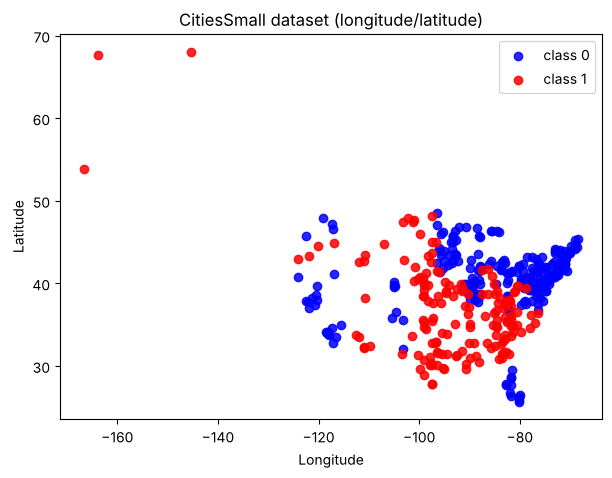

In [3]:
dataset = load_dataset("citiesSmall.pkl")
X = dataset["X"]
y = dataset["y"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Class balance:", {int(c): int((y==c).sum()) for c in np.unique(y)})

plt.figure()
plt.scatter(X[y==0, 0], X[y==0, 1], color="b", label="class 0", alpha=0.85)
plt.scatter(X[y==1, 0], X[y==1, 1], color="r", label="class 1", alpha=0.85)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.title("CitiesSmall dataset (longitude/latitude)")
plt.show()

## 2. Baseline: always predict the majority class
Any useful split has to beat this.

In [4]:
y_pred_majority = np.zeros_like(y) + mode(y)
baseline_error = np.mean(y_pred_majority != y)
print(f"Majority-class training error: {baseline_error:.3f}")

Majority-class training error: 0.415


## 3. Equality stump
Rounding longitude and latitude to whole degrees and splitting on equality isolates a single one-degree band of the map, the horizontal strip in the plot. That is only a small improvement over the baseline.

Evaluating model: DecisionStumpEquality
Error: 0.380


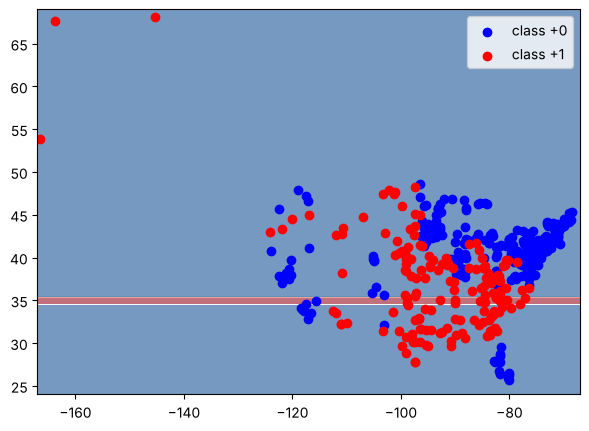

In [5]:
evalModel(DecisionStumpEquality, X, y)
plt.show()

## 4. Error-rate stump
This tries every observed value as a threshold, for every feature. Scoring each candidate on all $n$ points costs $O(n^2 d)$. A single well-placed split cuts the training error to about 25%.

Evaluating model: DecisionStumpErrorRate
Error: 0.253


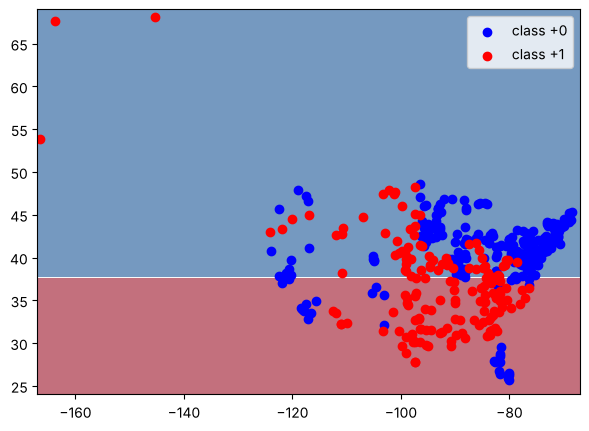

In [6]:
evalModel(DecisionStumpErrorRate, X, y)
plt.show()

## 5. Information-gain stump
At depth 1 the info-gain stump has a *higher* training error than the error-rate stump. That is expected, because it doesn't minimize error directly. It prefers splits that make the two sides purer, even when the majority label on each side stays the same. That choice pays off once the tree goes deeper (Section 7).

Evaluating model: DecisionStumpInfoGain


Error: 0.325


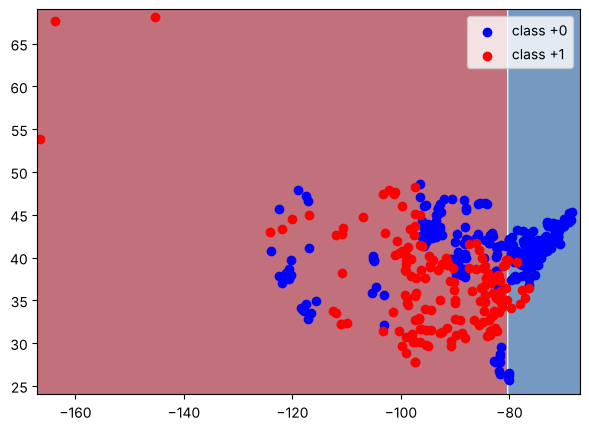

In [7]:
evalModel(DecisionStumpInfoGain, X, y)
plt.show()

## 6. A depth-2 tree

DecisionTree depth=2, stump=DecisionStumpInfoGain => train error 0.242


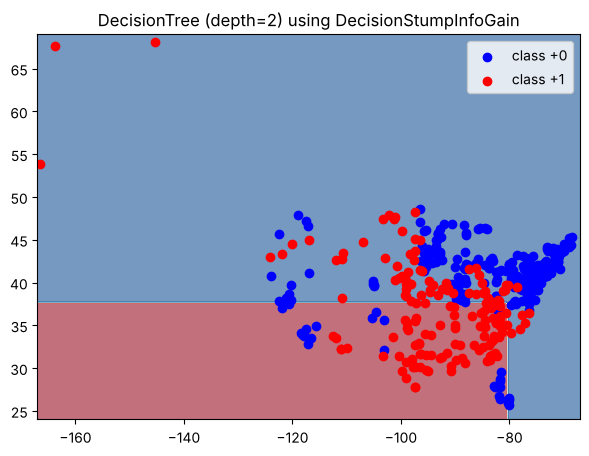

In [8]:
def fit_tree_and_plot(max_depth, stump_class):
    model = DecisionTree(max_depth=max_depth, stump_class=stump_class)
    model.fit(X, y)
    y_pred = model.predict(X)
    err = np.mean(y_pred != y)
    print(f"DecisionTree depth={max_depth}, stump={stump_class.__name__} => train error {err:.3f}")
    plot_classifier(model, X, y)
    plt.title(f"DecisionTree (depth={max_depth}) using {stump_class.__name__}")
    plt.show()
    return model, err

tree2_infogain, err2 = fit_tree_and_plot(max_depth=2, stump_class=DecisionStumpInfoGain)

## 7. Training error vs. depth, checked against scikit-learn
The training error for both splitting rules as the tree gets deeper, with scikit-learn's `DecisionTreeClassifier(criterion="entropy")` as a reference.

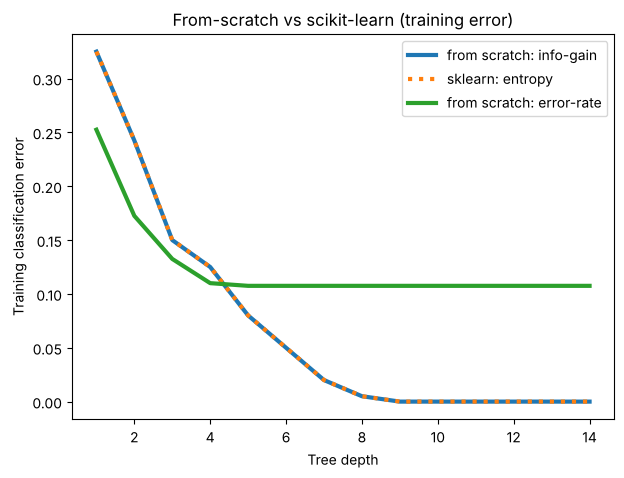

In [9]:
from sklearn.tree import DecisionTreeClassifier
depths = np.arange(1, 15)

err_errorrate = []
err_infogain = []

for depth in depths:
    m1 = DecisionTree(max_depth=depth, stump_class=DecisionStumpErrorRate)
    m1.fit(X, y)
    err_errorrate.append(np.mean(m1.predict(X) != y))

    m2 = DecisionTree(max_depth=depth, stump_class=DecisionStumpInfoGain)
    m2.fit(X, y)
    err_infogain.append(np.mean(m2.predict(X) != y))

sk_err = []
for depth in depths:
    sk = DecisionTreeClassifier(max_depth=int(depth), criterion="entropy", random_state=1)
    sk.fit(X, y)
    sk_err.append(np.mean(sk.predict(X) != y))

plt.figure()
plt.plot(depths, err_infogain, label="from scratch: info-gain", linewidth=3)
plt.plot(depths, sk_err, label="sklearn: entropy", linestyle=":", linewidth=3)
plt.plot(depths, err_errorrate, label="from scratch: error-rate", linewidth=3)
plt.xlabel("Tree depth")
plt.ylabel("Training classification error")
plt.legend()
plt.title("From-scratch vs scikit-learn (training error)")
plt.show()

* My info-gain tree matches scikit-learn's entropy tree at every depth (the two curves overlap). That is a good sign the implementation is correct.
* The error-rate tree gets stuck at about 11% from depth 5 on. When no single split reduces the number of mistakes, the error-rate stump doesn't split at all, even if a split would set up good splits further down. Information gain still finds splits that make the children purer, so it keeps improving and reaches 0% training error by depth 9.
* 0% training error means the deep tree has memorized the training set. The test error (16.1% at depth 5, see [k-NN vs. a decision tree](../01-k-nearest-neighbours/knn.ipynb)) is the number that reflects generalization.